# 07 · Correcting the optimiser's curse, and sizing the live test

Notebook 05 found that the optimised plan **overstates its own profit**: 34% at a $100 budget with no per-member cap. This is the *optimiser's curse*. Choosing the offers with the highest *predicted* profit also chooses the most over-estimated ones. Quantitative finance has the same problem: a portfolio optimised on sample means "maximises estimation error".

This notebook:
1. measures each prediction's uncertainty by refitting the champion on 30 bootstrap resamples of training members;
2. ranks offers by a **lower confidence bound** μ − z·σ (risk-averse) and compares it with the current plan and with empirical-Bayes **shrinkage**;
3. chooses z on **validation** using observed outcomes only, then checks on test against the ground truth and across 3 more random seeds;
4. checks what the new plan does to **fairness**;
5. sizes a live A/B test from real spending variance, with and without **CUPED**.

Code: `src/nectar/optimise/robust.py`, `src/nectar/evaluate/power.py`. The study is produced by `python -m nectar.optimise.robust`.

In [1]:
import os, json, warnings
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"; warnings.filterwarnings("ignore")
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from nectar import viz
from nectar.viz import BLUE, ORANGE, GREY, TEXT_2
from nectar.config import ROOT, PROCESSED_DIR, WAREHOUSE_PATH

viz.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
res = pd.read_csv(ROOT / "models" / "robust_eval.csv")
meta = json.loads((ROOT / "models" / "robust.json").read_text())
Z = meta["z"]; LCB = f"lcb z={Z}"
print(f"Risk level chosen on validation: z = {Z}  ({meta['n_models']} bootstrap models)")
test = res[res.split == "test"].copy()
test["overstatement"] = test.forecast / test.true_profit - 1

Risk level chosen on validation: z = 0.5  (30 bootstrap models)


## 1. The risk-aware plan earns more, at every budget

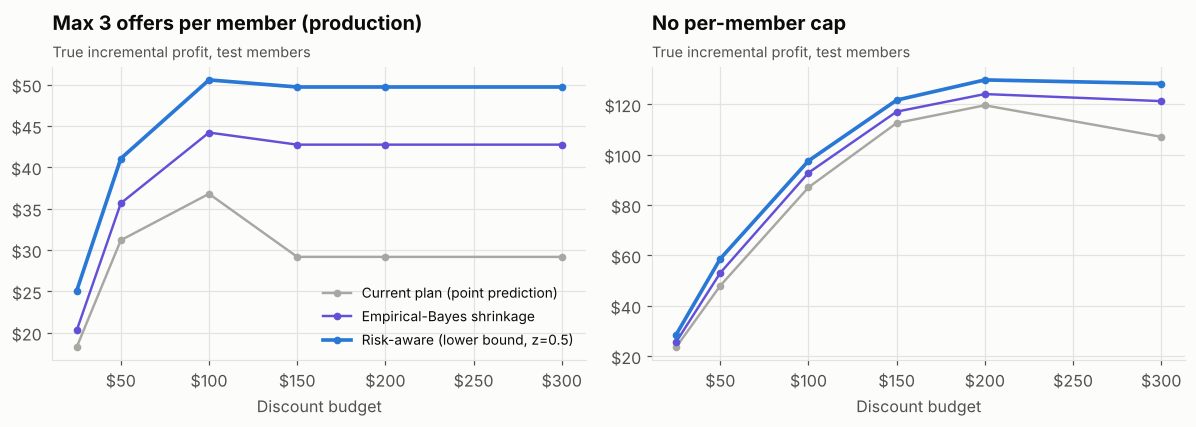

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, cap, title in [(axes[0], 3, "Max 3 offers per member (production)"),
                       (axes[1], 99, "No per-member cap")]:
    t = test[test.cap == cap]
    for name, col, label in [("point", GREY, "Current plan (point prediction)"),
                             ("shrink", "#6250d6", "Empirical-Bayes shrinkage"),
                             (LCB, BLUE, f"Risk-aware (lower bound, z={Z})")]:
        g = t[t.method == name].sort_values("budget")
        ax.plot(g.budget, g.true_profit, marker="o", ms=4, color=col, label=label,
                lw=2.4 if name == LCB else 1.6)
    ax.xaxis.set_major_formatter(viz.money(0)); ax.yaxis.set_major_formatter(viz.money(0))
    ax.set_xlabel("Discount budget"); ax.grid(axis="x")
    ax.set_title(title)
    viz.subtitle(ax, "True incremental profit, test members")
axes[0].legend(loc="lower right", fontsize=9)
fig.tight_layout()
viz.save(fig, "26_robust_profit"); fig

In [3]:
cmp = test[test.method.isin(["point", LCB])].pivot_table(
    index=["cap", "budget"], columns="method", values=["true_profit", "overstatement"])
cmp.columns = [f"{a} | {b}" for a, b in cmp.columns]
cmp["true profit gain"] = cmp[f"true_profit | {LCB}"] / cmp["true_profit | point"] - 1
cmp

overstatement | lcb z=0.5  overstatement | point  \
cap budget                                                     
3   25                           0.70                   1.61   
    50                           0.44                   1.16   
    100                          0.45                   1.33   
    150                          0.49                   2.08   
    200                          0.49                   2.08   
    300                          0.49                   2.08   
99  25                           0.68                   1.27   
    50                           0.21                   0.66   
    100                          0.06                   0.34   
    150                          0.01                   0.25   
    200                          0.03                   0.29   
    300                          0.05                   0.50   

            true_profit | lcb z=0.5  true_profit | point  true profit gain  
cap budget                                                                  
3   25                        25.08                18.27              0.37  
    50                        41.06                31.18              0.32  
    100                       50.56                36.79              0.37  
    150                       49.70                29.17              0.70  
    200                       49.70                29.17              0.70  
    300                       49.70                29.17              0.70  
99  25                        28.62                23.67              0.21  
    50                        58.72                48.01              0.22  
    100                       97.58                87.05              0.12  
    150                      121.68               112.58              0.08  
    200                      129.69               119.60              0.08  
    300                      128.24               107.11              0.20

With the 3-offer cap, the current plan gets *worse* as the budget grows past $100, because extra budget is spent on offers that only look good by chance. The risk-aware plan doesn't degrade. Shrinkage helps too ($37 → $44 at $100 with the cap), but less: one global prior pulls every estimate by a similar amount, while the lower bound penalises exactly the uncertain offers.

## 2. The plan's own forecast becomes honest

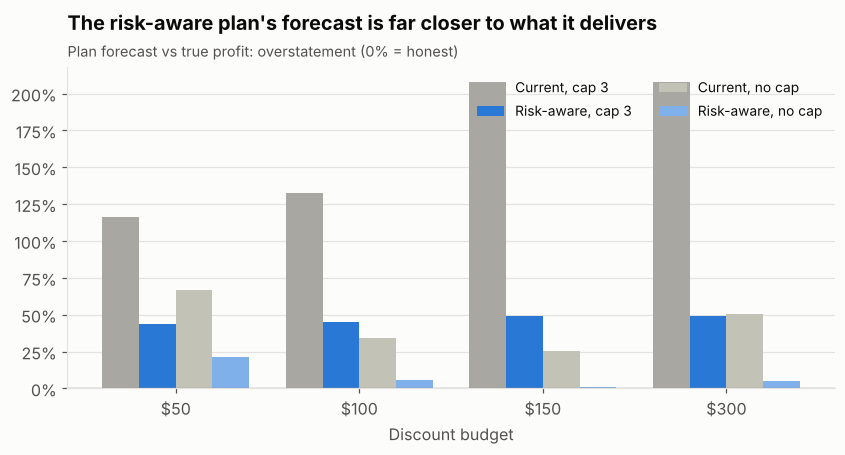

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
budgets = [50, 100, 150, 300]
x = np.arange(len(budgets)); w = 0.2
for i, (cap, name, col, lab) in enumerate([(3, "point", GREY, "Current, cap 3"), (3, LCB, BLUE, "Risk-aware, cap 3"),
                                            (99, "point", "#c3c2b7", "Current, no cap"), (99, LCB, "#7fb0ea", "Risk-aware, no cap")]):
    g = test[(test.cap == cap) & (test.method == name)].set_index("budget").loc[budgets]
    ax.bar(x + (i - 1.5) * w, g.overstatement, width=w, color=col, label=lab)
ax.axhline(0, color=TEXT_2, lw=0.8)
ax.set_xticks(x, [viz.money(0)(b) for b in budgets]); ax.set_xlabel("Discount budget")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title("The risk-aware plan's forecast is far closer to what it delivers")
viz.subtitle(ax, "Plan forecast vs true profit: overstatement (0% = honest)")
ax.legend(ncol=2, fontsize=9, loc="upper right")
viz.save(fig, "27_robust_overstatement"); fig

## 3. z was chosen without looking at the answer

The risk level is chosen on the **validation** split using the observed-outcome (IPW) estimate of each plan's profit, averaged over budgets of $50, $100 and $150 and both cap settings. The chart compares that with what each z truly earns on test.

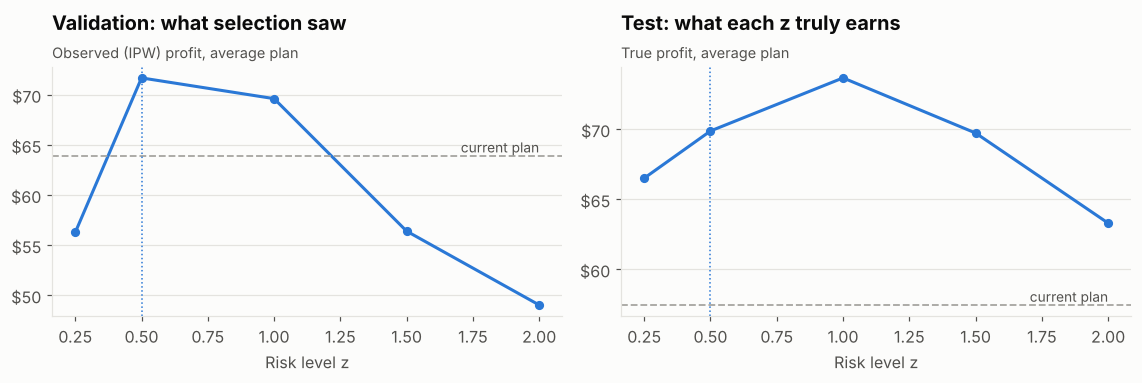

In [5]:
lcb = res[res.method.str.startswith("lcb") & res.budget.isin([50, 100, 150])].copy()
lcb["z"] = lcb.method.str.split("=").str[1].astype(float)
sel = lcb[lcb.split == "valid"].groupby("z")["observed_profit"].mean()
tru = lcb[lcb.split == "test"].groupby("z")["true_profit"].mean()
point_valid = res[(res.split == "valid") & (res.method == "point") & res.budget.isin([50, 100, 150])]["observed_profit"].mean()
point_test = test[(test.method == "point") & test.budget.isin([50, 100, 150])].true_profit.mean()
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for ax, s, ref, title, sub in [(axes[0], sel, point_valid, "Validation: what selection saw", "Observed (IPW) profit, average plan"),
                               (axes[1], tru, point_test, "Test: what each z truly earns", "True profit, average plan")]:
    ax.plot(s.index, s.values, color=BLUE, marker="o", ms=5)
    ax.axhline(ref, color=GREY, ls="--", lw=1.2)
    ax.text(s.index.max(), ref, " current plan", va="bottom", ha="right", fontsize=9, color=TEXT_2)
    ax.axvline(Z, color=BLUE, ls=":", lw=1)
    ax.yaxis.set_major_formatter(viz.money(0)); ax.set_xlabel("Risk level z")
    ax.set_title(title); viz.subtitle(ax, sub)
fig.tight_layout()
viz.save(fig, "28_robust_selection"); fig

Validation picks z = 0.5. On test, z = 1.0 would have been better, but z = 0.5 still beats the current plan. We keep the validation choice, because switching after seeing test results would be selection on the test set. This is the same discipline as champion selection in notebook 04.

## 4. Is it robust to the random seed?

In [6]:
from nectar.features.schema import model_matrix
from nectar.models.train import load_experiment, split_by_member
from nectar.optimise.cost_model import DiscountCostModel
from nectar.optimise.robust import BaggedUplift, lower_bound, _plan

df = load_experiment(); df["split"] = split_by_member(df, 0); X = model_matrix(df)
tr = (df.split == "train").to_numpy()
cost = DiscountCostModel().fit(df[tr])
scores = pd.read_parquet(PROCESSED_DIR / "holdout_scores.parquet")
p = df[df.split == "test"].copy()
s = scores[scores.split == "test"].set_index(["member_id", "offer_id"])["score__X-learner"]
p["point"] = s.reindex(pd.MultiIndex.from_frame(p[["member_id", "offer_id"]])).to_numpy()
p["cost"] = cost.predict(p)
gt = p.gt_profit_uplift.to_numpy()
rows = []
for seed in (1, 2, 3):
    bag = BaggedUplift(seed=seed * 100).fit(X[tr], df.treatment.to_numpy()[tr],
                                            df.gross_profit.to_numpy()[tr], df.member_id.to_numpy()[tr])
    mu, sd = bag.predict(model_matrix(p))
    for cap in (3, 99):
        for b in (50, 100, 150, 300):
            rows.append({"seed": seed, "cap": cap, "budget": b,
                         "current": gt[_plan(p, p.point.to_numpy(), b, cap)].sum(),
                         "risk_aware": gt[_plan(p, lower_bound(mu, sd, Z), b, cap)].sum()})
seeds = pd.DataFrame(rows); seeds["gain"] = seeds.risk_aware / seeds.current - 1
print(f"Risk-aware beats the current plan in {(seeds.risk_aware > seeds.current).sum()} of {len(seeds)} seed x cap x budget checks")
seeds.groupby(["cap", "budget"]).gain.agg(["min", "max"]).style.format("{:+.0%}")

Risk-aware beats the current plan in 24 of 24 seed x cap x budget checks


## 5. The fairness trade-off

In [7]:
from nectar.serving.bundle import build_bundle
from nectar.evaluate.fairness import group_report, member_plan

con = duckdb.connect(str(WAREHOUSE_PATH), read_only=True)
demo = con.execute("SELECT member_id, age_group, income_level, household_size, kids, trips FROM marts.dim_member").df()
plans = {"Current (point)": build_bundle(600, 3, risk_aware=False).candidates,
         "Risk-aware": build_bundle(600, 3, risk_aware=True).candidates}
rows = []
for name, cand in plans.items():
    m = member_plan(cand).merge(demo, on="member_id")
    rows.append({"plan": name, "attribute": "all members", "lowest reach ratio": np.nan,
                 "flagged": "", "reach": m.reached.mean(), "offers": int(cand.selected.sum())})
    for col in ["age_group", "household_size", "kids", "income_level"]:
        r = group_report(m.dropna(subset=["age_group"]), col)
        j = r[r.judged]
        rows.append({"plan": name, "attribute": col, "lowest reach ratio": j.reach_ratio.min(),
                     "flagged": ", ".join(map(str, j.index[j.flag])), "reach": np.nan, "offers": np.nan})
fair = pd.DataFrame(rows)
fair.pivot_table(index="attribute", columns="plan", values="lowest reach ratio", aggfunc="first")

plan,Current (point),Risk-aware
attribute,,
age_group,0.85,0.80
household_size,0.88,0.75
income_level,0.71,0.62
kids,0.90,0.85


In [8]:
fair[fair.flagged != ""][["plan", "attribute", "flagged"]]

,plan,attribute,flagged
4,Current (point),income_level,"Level9, Level8"
7,Risk-aware,household_size,3
9,Risk-aware,income_level,"Level9, Level8"


In [9]:
ra = plans["Risk-aware"]
mm = ra.groupby("member_id").agg(sd=("value_sd", "mean"), reached=("selected", "any")).reset_index().merge(demo, on="member_id")
mm["trips_quartile"] = pd.qcut(mm.trips, 4, labels=["Q1 fewest", "Q2", "Q3", "Q4 most"])
mech = mm.groupby("trips_quartile", observed=True).agg(mean_uncertainty=("sd", "mean"), reach=("reached", "mean"))
print(f"corr(log trips, uncertainty) = {np.corrcoef(np.log(mm.trips), mm.sd)[0, 1]:.2f}")
inc = mm.dropna(subset=["income_level"]).groupby("income_level").agg(members=("member_id", "size"), mean_uncertainty=("sd", "mean"), reach=("reached", "mean"))
mech, inc.sort_values("mean_uncertainty")

corr(log trips, uncertainty) = 0.56


(                mean_uncertainty  reach
 trips_quartile                         
 Q1 fewest                   0.04   0.97
 Q2                          0.05   0.86
 Q3                          0.06   0.67
 Q4 most                     0.08   0.38,
               members  mean_uncertainty  reach
 income_level                                  
 Level2             74              0.06   0.54
 Level4            172              0.07   0.54
 Level3             77              0.07   0.52
 Level7             34              0.07   0.59
 Level1             61              0.07   0.51
 Level5            192              0.08   0.56
 Level11             5              0.08   0.40
 Level6             96              0.08   0.57
 Level10            11              0.09   0.45
 Level8             38              0.09   0.42
 Level9             30              0.10   0.37
 Level12            11              0.11   0.27)

**What drives it.** Penalising uncertainty penalises the members the model is least sure about. Here those are the **most frequent shoppers**: their bigger, more varied baskets put more profit at stake per offer, and that profit is harder to predict. Income levels 8 and 9 have the highest average uncertainty, so their reach falls furthest. The groups are small (30–38 members), so this is a flag for review, not proof.

**Decision this needs from the business:** take the higher profit and honest forecast, and add a minimum-reach constraint per group to the optimiser where it matters, or use a smaller z. The pipeline exposes `--no-risk` to fall back to the point plan.

## 6. How big must a live test be?

In [10]:
from nectar.evaluate.power import cuped, member_outcomes, sample_size_per_arm, minimum_detectable_effect

y, x = member_outcomes(con)
ya, theta = cuped(y, x)
rho = np.corrcoef(x, y)[0, 1]; sd = y.std(ddof=1)
print(f"{len(y):,} active members | 4-week gross margin: mean ${y.mean():.2f}, sd ${sd:.2f}")
print(f"Pre-period (12 weeks) correlation rho = {rho:.2f} -> CUPED removes {1 - ya.var(ddof=1) / y.var(ddof=1):.0%} of the variance")
power = pd.DataFrame([{"effect per member per cycle": d,
                       "members per arm": sample_size_per_arm(sd, d),
                       "with CUPED": sample_size_per_arm(sd, d, rho=rho)} for d in (0.25, 0.5, 1.0, 2.0)])
power.style.format({"effect per member per cycle": "${:.2f}", "members per arm": "{:,}", "with CUPED": "{:,}"})

2,407 active members | 4-week gross margin: mean $43.50, sd $52.85
Pre-period (12 weeks) correlation rho = 0.80 -> CUPED removes 63% of the variance


,effect per member per cycle,members per arm,with CUPED
0,$0.25,"701,576","257,135"
1,$0.50,"175,394","64,284"
2,$1.00,"43,849","16,071"
3,$2.00,"10,963","4,018"


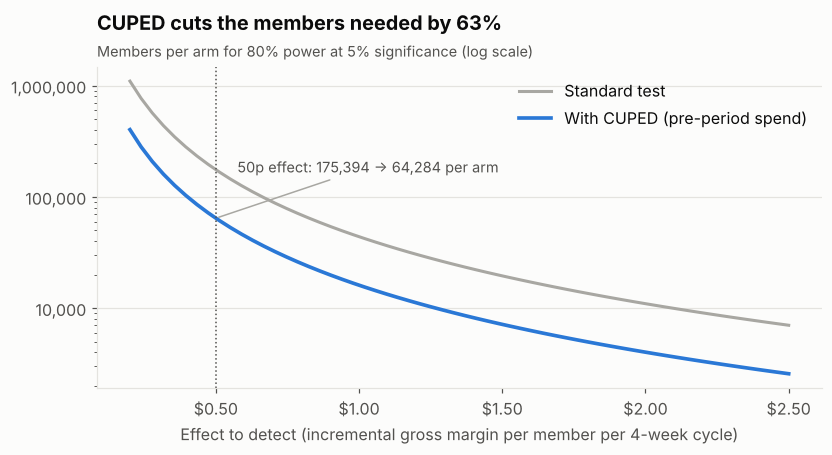

In [11]:
d = np.linspace(0.2, 2.5, 60)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(d, [sample_size_per_arm(sd, v) for v in d], color=GREY, lw=2, label="Standard test")
ax.plot(d, [sample_size_per_arm(sd, v, rho=rho) for v in d], color=BLUE, lw=2.4, label="With CUPED (pre-period spend)")
ax.axvline(0.5, color=TEXT_2, ls=":", lw=1)
n0, n1 = sample_size_per_arm(sd, 0.5), sample_size_per_arm(sd, 0.5, rho=rho)
ax.annotate(f"50p effect: {n0:,} → {n1:,} per arm", (0.5, n1), xytext=(14, 30), textcoords="offset points",
            fontsize=9.5, color=TEXT_2, arrowprops=dict(arrowstyle="-", color=GREY))
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.xaxis.set_major_formatter(viz.money(2))
ax.set_xlabel("Effect to detect (incremental gross margin per member per 4-week cycle)")
ax.set_title(f"CUPED cuts the members needed by {1 - n1 / n0:.0%}")
viz.subtitle(ax, "Members per arm for 80% power at 5% significance (log scale)")
ax.legend(loc="upper right")
viz.save(fig, "29_test_power"); fig

## Summary

| | Result |
|---|---|
| Problem | The plan picked offers whose profit was over-predicted, overstating its own profit by 25–208% depending on cap and budget |
| Fix | Uncertainty from 30 bootstrap refits; rank by the lower bound μ − 0.5σ, with 0.5 chosen on validation |
| Profit (test, ground truth) | Beats the current plan at every budget and cap; **+23% to +38% at $100 with the 3-offer cap** and +4% to +19% without, across 4 seeds (24/24 checks with 3 extra seeds) |
| Forecast honesty | Overstatement at $100: 133% → 45% with the cap, 34% → 6% without |
| Trade-off | Reaches fewer members and widens group reach gaps, so it needs business sign-off or a group-reach constraint |
| Live test | A 50p effect needs ~175k members per arm, or ~64k with CUPED (pre-period spend removes 63% of variance) |